# Passenger Demand Forecasting

The rolling XGBoost forecast fits on one calendar month at a time and predicts the next month through an inclusive end date, up to 24 months ahead. It uses the passenger data and feature definitions from [`modeling.ipynb`](modeling.ipynb).

The model comparison fits XGBoost, SARIMAX, and the two ensembles. The main XGBoost run uses 600 trees and tunes its settings for WAPE on forecast months 13–24 using Optuna before the final holdout. The history-based feature sets use the same directional route's demand from 1, 12, and 24 months earlier. The experiment saves its forecast to `data/processed/passenger_demand_forecast_24m.csv`.

In [ ]:
import json
import sys
from pathlib import Path

# Reuse the canonical CSV validation and feature engineering from modeling.ipynb.
data_dir_candidates = [
    Path.cwd() / "team-06-modeling",
    Path.cwd(),
    Path.cwd().parent,
]
DATA_DIR = next(
    (
        path
        for path in data_dir_candidates
        if (path / "AA_PAX_FORECASTING.csv").is_file()
        and (path / "AA_AIRPORT_INFO.csv").is_file()
    ),
    None,
)
if DATA_DIR is None:
    raise FileNotFoundError(
        "Could not find both CSV files. Place them in team-06-modeling/ "
        "or update DATA_DIR to their folder."
    )

modeling_path = DATA_DIR / "notebooks" / "modeling.ipynb"
modeling_notebook = json.loads(modeling_path.read_text(encoding="utf-8"))
for cell_number, cell in enumerate(modeling_notebook["cells"], start=1):
    if cell["cell_type"] == "code":
        source = "".join(cell["source"])
        exec(compile(source, f"{modeling_path} cell {cell_number}", "exec"), globals())

## Model comparison and Bayesian tuning

Set `tuning_trials` to choose the Optuna trial budget, or set it to zero to use the shared defaults. The first trial evaluates the default settings. The holdout score table reports WAPE and signed bias for months 13–24.

In [ ]:
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter

sys.path.insert(0, str(DATA_DIR / "models"))
import importlib
import forecasting as forecasting_module
importlib.reload(forecasting_module)
from forecasting import run_forecasting_experiment

tuning_trials = 20

forecasting_result = run_forecasting_experiment(
    features=features,
    passengers=passengers,
    feature_sets=FEATURE_SETS,
    data_dir=DATA_DIR,
    target=TARGET,
    origin=ORIGIN,
    destination=DESTINATION,
    month=MONTH,
    month_index=MONTH_INDEX,
    tuning_trials=tuning_trials,
)

test_metrics = forecasting_result["test_metrics"]
backtest_predictions = forecasting_result["backtest_predictions"]
forecast = forecasting_result["forecast"]
best_model = forecasting_result["best_model"]
print(f"Selected model: {best_model}")

XGBoost feature-set validation (12 months, prior to tuning)


,Feature_Set,WAPE,MAE,Bias,WAPE_1_12,WAPE_1_24
0,2_route_calendar_geography,0.204849,670.921518,-0.041681,0.204849,NaN
1,1A_route_calendar,0.231162,757.101842,-0.045653,0.231162,NaN
2,3_combined,0.594531,1947.206737,-0.561656,0.594531,NaN
3,1B_route_calendar_history,0.631582,2068.558046,-0.605261,0.631582,NaN


## Rolling one-month recursive forecast

Set `rolling_forecast_origin` to the last month of actuals the model can use and `rolling_forecast_end` to the last month to predict. Dates are interpreted as calendar months. With both set to `None`, the run starts after the latest observed month and forecasts 24 months.

The first fit uses routes and observed demand from the origin month. Each later fit uses the preceding month's predicted demand for those same routes. Earlier history supplies lag and rolling features. The two-year lag uses observed demand through month 24 wherever the route has data. The rolling run uses the tuned settings when its origin is at or after the tuning validation cutoff. Any actuals after the origin are joined separately in `rolling_backtest` after predictions are generated. The preview shows each route's WAPE when its complete evaluation window is available.

In [ ]:
import importlib

sys.path.insert(0, str(DATA_DIR / "models"))
import forecasting as forecasting_module

importlib.reload(forecasting_module)


def rolling_monthly_forecast(
    passengers, features, origin_month, end_month=None, xgb_params=None
):
    """Fit on one month and predict the next through the inclusive end month."""
    origin_month = pd.Period(origin_month, freq="M").to_timestamp()
    if pd.isna(origin_month):
        raise ValueError("The forecast origin must be an observed month.")
    if end_month is None:
        end_month = origin_month + pd.DateOffset(months=24)
    else:
        end_month = pd.Period(end_month, freq="M").to_timestamp()
    if pd.isna(end_month):
        raise ValueError("The forecast end must be a calendar month.")
    horizon = (end_month.year - origin_month.year) * 12 + (
        end_month.month - origin_month.month
    )
    if not 1 <= horizon <= 24:
        raise ValueError("The forecast end must be 1 to 24 months after the origin.")

    feature_set_name = "3_combined"
    feature_columns = FEATURE_SETS[feature_set_name]
    row_keys = ROUTE_COLUMNS + [MONTH]
    history_columns = row_keys + [MONTH_INDEX, TARGET]
    training = features.loc[
        features[MONTH] == origin_month, feature_columns + [MONTH, MONTH_INDEX, TARGET]
    ].copy()
    if training.empty:
        raise ValueError(f"No training rows in the origin month {origin_month:%Y-%m}.")

    first_test_month = origin_month + pd.DateOffset(months=1)
    test_months = pd.date_range(first_test_month, end_month, freq="MS")
    # Keep the lookback needed for lag and rolling features, frozen at the origin.
    history = passengers.loc[
        passengers[MONTH].between(first_test_month - pd.DateOffset(months=24), origin_month),
        history_columns,
    ].copy()
    outputs = []
    for step, test_month in enumerate(test_months, start=1):
        train_month = test_month - pd.DateOffset(months=1)
        # The shared fit helper uses the first supplied feature month as TIME_INDEX zero.
        training["TIME_INDEX"] = 0
        predictions = forecasting_module._fit_and_forecast_xgb(
            training, history, FEATURE_SETS, feature_set_name, ROUTE_COLUMNS,
            MONTH, MONTH_INDEX, TARGET, train_month, 1, xgb_params,
        )
        predictions["HORIZON"] = step
        outputs.append(predictions)
        if step == horizon:
            break

        # Recreate the test features from prior history before adding this month's prediction.
        training = forecasting_module._make_future_features(
            history, training, feature_columns + [MONTH, MONTH_INDEX], ROUTE_COLUMNS,
            MONTH, MONTH_INDEX, TARGET, test_month, int(training[MONTH_INDEX].iloc[0]),
            ["ROUTE_ID", *geographic_features],
        ).merge(
            predictions[row_keys + ["XGB_PRED"]].rename(columns={"XGB_PRED": TARGET}),
            on=row_keys,
            validate="one_to_one",
        )
        history = pd.concat([history, training[history_columns]], ignore_index=True)

    return pd.concat(outputs, ignore_index=True)

In [ ]:
rolling_forecast_origin = None  # Last actual month, for example "2024-12"
rolling_forecast_end = None  # Inclusive end month, for example "2025-06"

rolling_origin = (
    passengers[MONTH].max() if rolling_forecast_origin is None
    else pd.Period(rolling_forecast_origin, freq="M").to_timestamp()
)
tuning_result = forecasting_result["tuning_result"]
rolling_xgb_params = (
    tuning_result["best_params"]
    if tuning_result is not None and rolling_origin >= tuning_result["validation_end"]
    else None
)
rolling_forecast = rolling_monthly_forecast(
    passengers, features, rolling_origin, rolling_forecast_end, xgb_params=rolling_xgb_params,
)
# Join realized demand only after the recursive forecast has finished.
rolling_backtest = rolling_forecast.merge(
    passengers[ROUTE_COLUMNS + [MONTH, TARGET]],
    on=ROUTE_COLUMNS + [MONTH],
    how="inner",
    validate="one_to_one",
)
print(
    f"Forecasted {rolling_forecast['HORIZON'].nunique()} months through "
    f"{rolling_forecast[MONTH].max():%Y-%m} across "
    f"{rolling_forecast[ROUTE_COLUMNS].drop_duplicates().shape[0]:,} routes."
)

In [ ]:
importlib.reload(forecasting_module)

rolling_preview = rolling_forecast.head()
preview_scores = []
for origin, destination in rolling_preview[ROUTE_COLUMNS].itertuples(index=False, name=None):
    route_actuals = rolling_backtest.loc[
        rolling_backtest[ORIGIN].eq(origin) & rolling_backtest[DESTINATION].eq(destination)
    ]
    preview_scores.append(
        forecasting_module._wape_for_forecast_windows(route_actuals, "XGB_PRED", TARGET)
    )
rolling_preview.join(pd.DataFrame(preview_scores, index=rolling_preview.index))

,ORG_AIRPRT,DES_AIRPRT,MONTH_START,HORIZON,XGB_PRED,WAPE_1_12,WAPE_1_24
0,ABQ,ALB,2026-08-01,1,353.302795,NaN,NaN
1,PDX,YYZ,2026-08-01,1,2228.077637,NaN,NaN
2,PDX,ZRH,2026-08-01,1,672.882690,NaN,NaN
3,PHL,ABQ,2026-08-01,1,2170.866455,NaN,NaN
4,PHL,ALB,2026-08-01,1,626.643066,NaN,NaN


## Holdout accuracy by model

WAPE and RMSSE are shown on separate axes because they have different scales. All scores use matched route-months. The table includes WAPE across all evaluated months, months 1–12, and months 1–24. With the predictions still in memory, rerun this chart cell to refresh the WAPE columns.

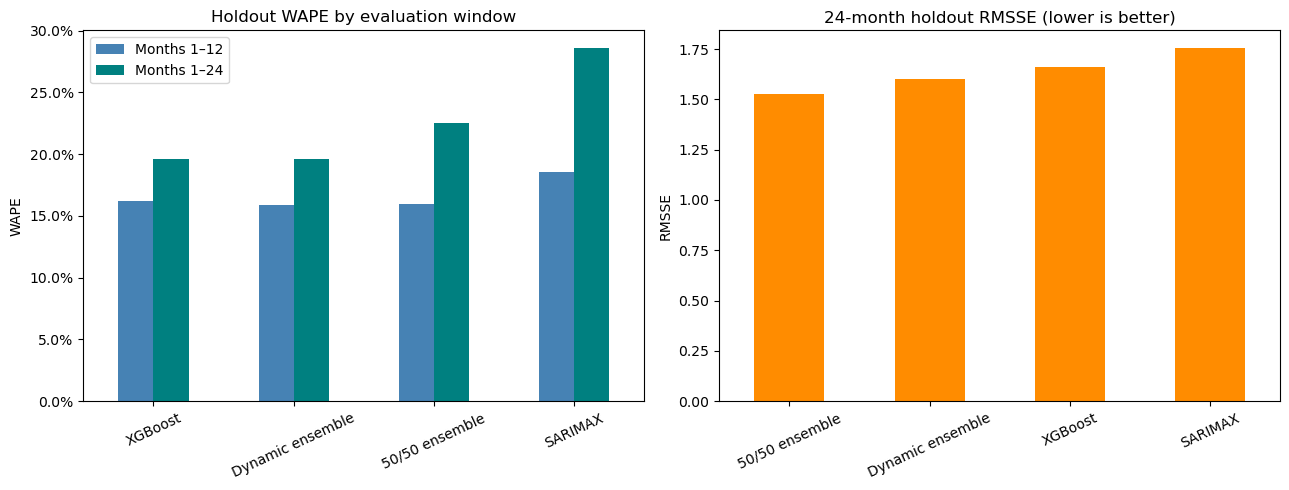

,Model,WAPE,WAPE_1_12,WAPE_1_24,MAE,Bias,RMSSE,RMSSE_Routes,RMSSE_Route_Coverage,WAPE_13_24,Bias_13_24
0,XGBoost,0.196270,0.162046,0.196270,617.748029,0.090653,1.660721,17119,1.0,0.232836,0.127911
1,SARIMAX,0.285977,0.185839,0.285977,900.093859,0.210145,1.755039,17119,1.0,0.392968,0.330659
2,50/50 ensemble,0.225104,0.159616,0.225104,708.499967,0.151119,1.526908,17119,1.0,0.295074,0.230812
3,Dynamic ensemble,0.196428,0.158645,0.196428,618.244240,0.099300,1.599250,17119,1.0,0.236796,0.140784


In [ ]:
importlib.reload(forecasting_module)
test_metrics = forecasting_module._add_wape_windows(test_metrics, backtest_predictions, TARGET)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
window_labels = {"WAPE_1_12": "Months 1–12", "WAPE_1_24": "Months 1–24"}
for column, label in window_labels.items():
    if test_metrics[column].isna().all():
        window_labels[column] = f"{label} (n/a)"
test_metrics.sort_values("WAPE").rename(columns=window_labels).plot.bar(
    x="Model", y=list(window_labels.values()), ax=axes[0], color=["steelblue", "teal"]
)
axes[0].set_title("Holdout WAPE by evaluation window")
axes[0].set_xlabel("")
axes[0].set_ylabel("WAPE")
axes[0].yaxis.set_major_formatter(PercentFormatter(1.0))
axes[0].tick_params(axis="x", rotation=25)

test_metrics.sort_values("RMSSE").plot.bar(
    x="Model", y="RMSSE", ax=axes[1], legend=False, color="darkorange"
)
axes[1].set_title("24-month holdout RMSSE (lower is better)")
axes[1].set_xlabel("")
axes[1].set_ylabel("RMSSE")
axes[1].tick_params(axis="x", rotation=25)
fig.tight_layout()
plt.show()

test_metrics

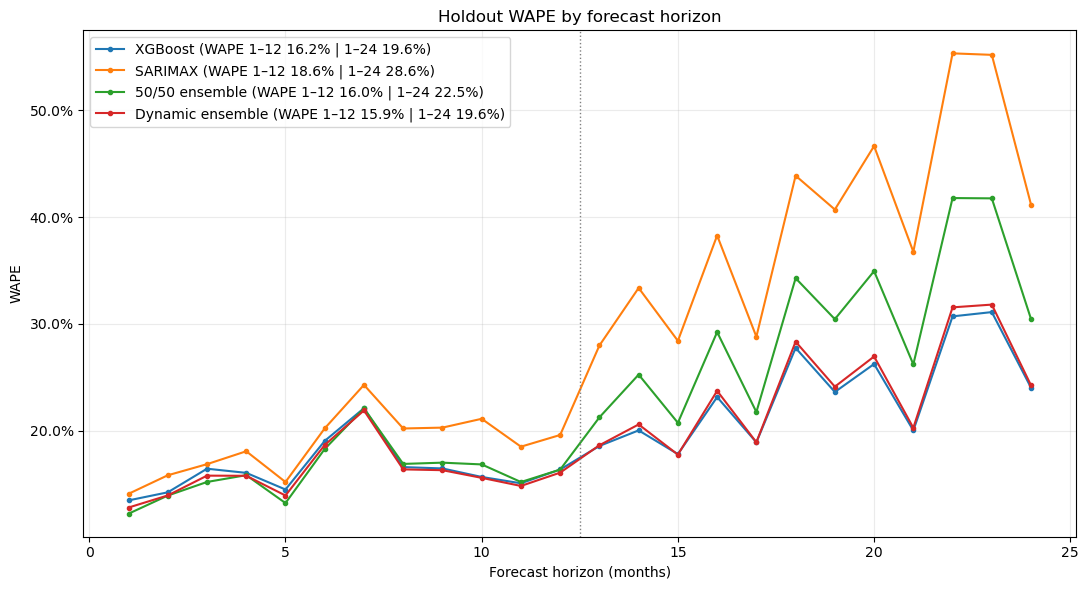

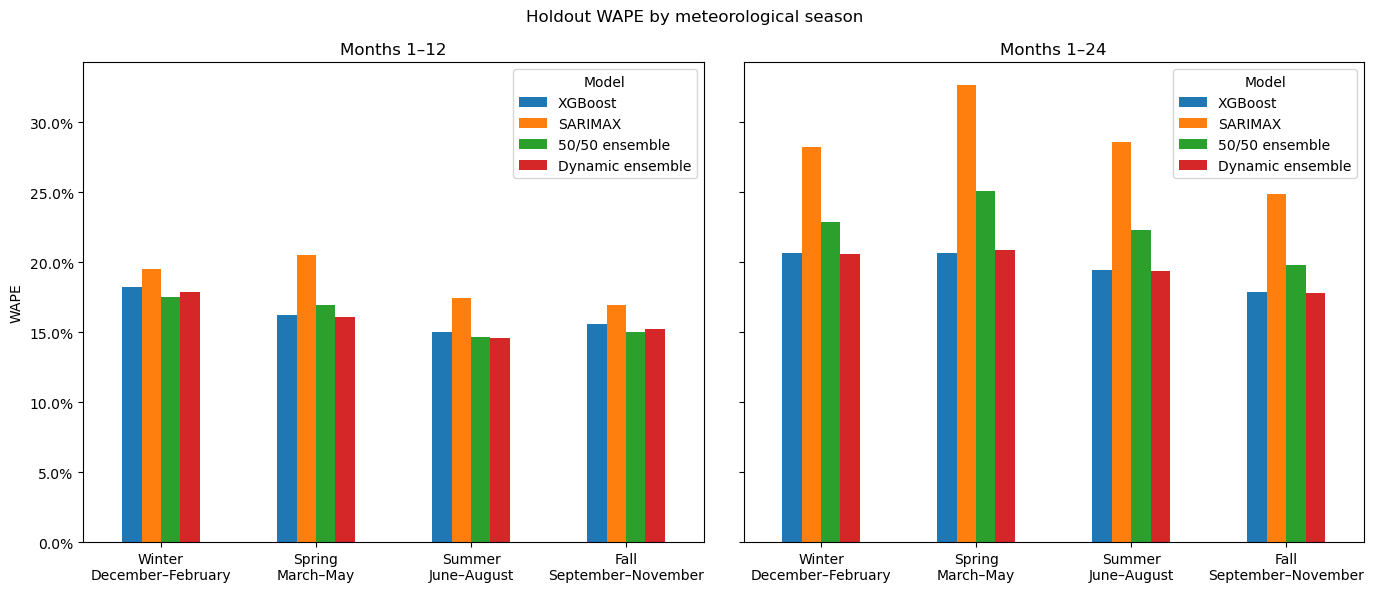

In [ ]:
importlib.reload(forecasting_module)
prediction_columns = forecasting_module._PREDICTION_COLUMNS
holdout_wape = forecasting_module._add_wape_windows(
    test_metrics, backtest_predictions, TARGET
).set_index("Model")

def grouped_wape(frame, group_columns):
    rows = []
    for model_name, prediction_column in prediction_columns.items():
        model_rows = frame[group_columns + [TARGET, prediction_column]].copy()
        model_rows["ABS_ERROR"] = (
            model_rows[prediction_column] - model_rows[TARGET]
        ).abs()
        grouped = model_rows.groupby(
            group_columns, as_index=False, observed=True
        ).agg(ABS_ERROR=("ABS_ERROR", "sum"), ACTUAL=(TARGET, "sum"))
        grouped["WAPE"] = grouped["ABS_ERROR"] / grouped["ACTUAL"].where(grouped["ACTUAL"] > 0)
        grouped["Model"] = model_name
        rows.append(grouped)
    return pd.concat(rows, ignore_index=True)

horizon_metrics = grouped_wape(backtest_predictions, ["HORIZON"])
fig, ax = plt.subplots(figsize=(11, 6))
for model_name in prediction_columns:
    model_rows = horizon_metrics.loc[horizon_metrics["Model"] == model_name]
    ax.plot(
        model_rows["HORIZON"],
        model_rows["WAPE"],
        marker="o",
        markersize=3,
        label=f"{model_name} ({forecasting_module._wape_window_label(holdout_wape.loc[model_name])})",
    )
ax.axvline(12.5, color="gray", linestyle=":", linewidth=1)
ax.set_title("Holdout WAPE by forecast horizon")
ax.set_xlabel("Forecast horizon (months)")
ax.set_ylabel("WAPE")
ax.yaxis.set_major_formatter(PercentFormatter(1.0))
ax.grid(True, alpha=0.25)
ax.legend()
fig.tight_layout()
plt.show()

seasonal_holdout = backtest_predictions.assign(
    SEASON=backtest_predictions[MONTH].dt.month.map({
        12: "DJF", 1: "DJF", 2: "DJF",
        3: "MAM", 4: "MAM", 5: "MAM",
        6: "JJA", 7: "JJA", 8: "JJA",
        9: "SON", 10: "SON", 11: "SON",
    })
)
season_labels = {
    "DJF": "Winter\nDecember–February",
    "MAM": "Spring\nMarch–May",
    "JJA": "Summer\nJune–August",
    "SON": "Fall\nSeptember–November",
}
fig, axes = plt.subplots(1, 2, figsize=(14, 6), sharey=True)
for axis, end in zip(axes, (12, 24)):
    window = seasonal_holdout.loc[seasonal_holdout["HORIZON"].between(1, end)]
    if window["HORIZON"].nunique() == end:
        season_metrics = grouped_wape(window, ["SEASON"])
        season_table = season_metrics.pivot(
            index="SEASON", columns="Model", values="WAPE"
        ).reindex(
            index=list(season_labels), columns=list(prediction_columns)
        ).rename(index=season_labels)
        season_table.plot.bar(ax=axis)
        axis.legend(title="Model")
    else:
        axis.text(0.5, 0.5, "WAPE unavailable", ha="center", transform=axis.transAxes)
    axis.set_title(f"Months 1–{end}")
    axis.set_xlabel("")
    axis.set_ylabel("WAPE")
    axis.yaxis.set_major_formatter(PercentFormatter(1.0))
    axis.tick_params(axis="x", rotation=0)
fig.suptitle("Holdout WAPE by meteorological season")
fig.tight_layout()
plt.show()

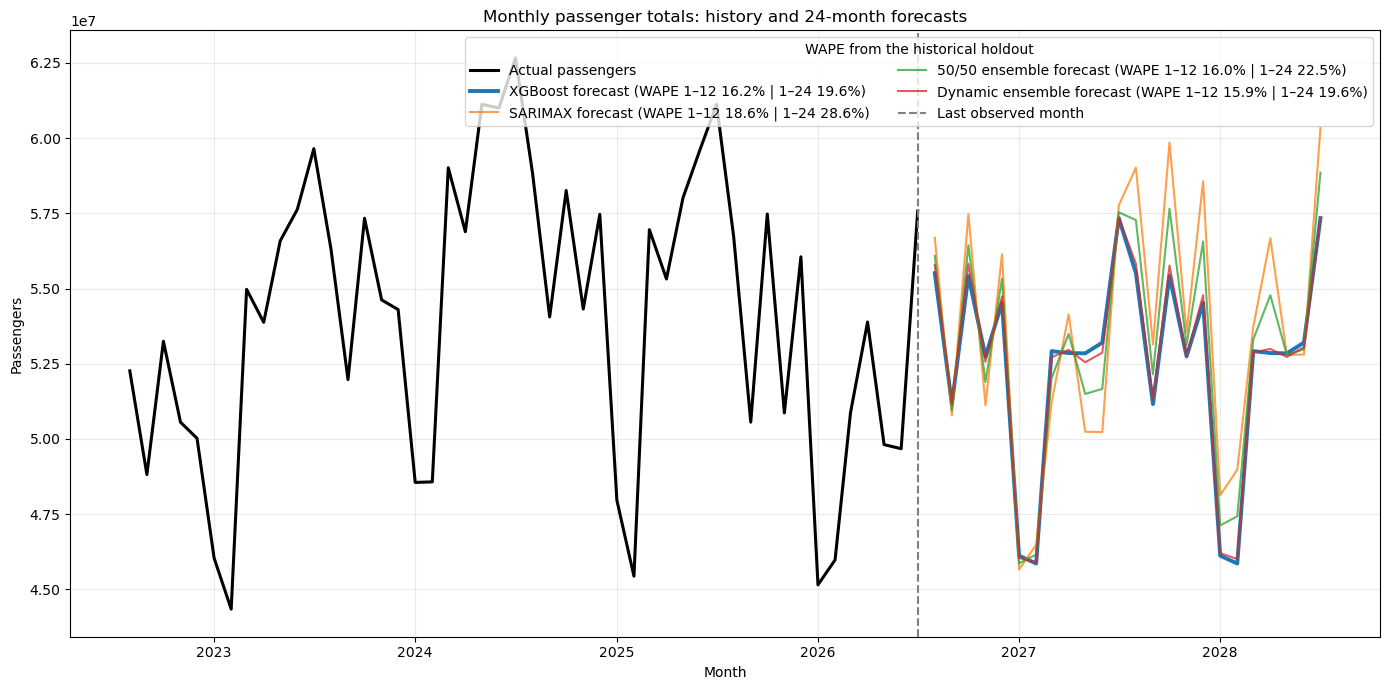

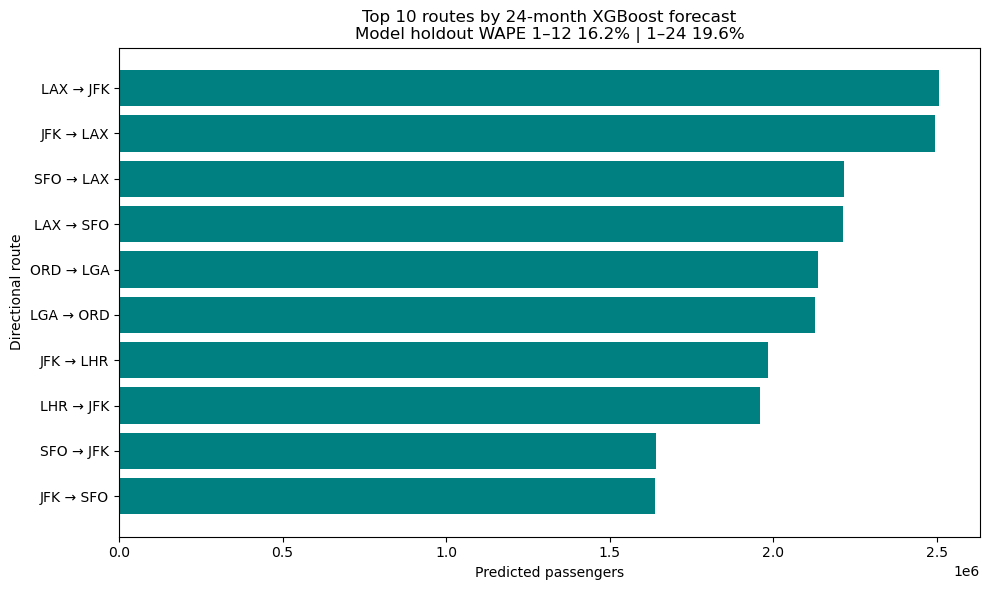

In [ ]:
importlib.reload(forecasting_module)
prediction_columns = forecasting_module._PREDICTION_COLUMNS
holdout_wape = forecasting_module._add_wape_windows(
    test_metrics, backtest_predictions, TARGET
).set_index("Model")

actual_history = (
    passengers.groupby(MONTH, as_index=False)[TARGET]
    .sum()
    .tail(48)
)
future_totals = forecast.groupby(MONTH, as_index=False)[
    ["XGB_PRED", "SARIMAX_PRED", "WEIGHTED_50_50_PRED", "DYNAMIC_PRED"]
].sum()
selected_prediction = prediction_columns[best_model]
latest_actual_month = passengers[MONTH].max()

fig, ax = plt.subplots(figsize=(14, 7))
ax.plot(
    actual_history[MONTH],
    actual_history[TARGET],
    color="black",
    linewidth=2.2,
    label="Actual passengers",
)
for model_name, prediction_column in prediction_columns.items():
    ax.plot(
        future_totals[MONTH],
        future_totals[prediction_column],
        linewidth=2.8 if prediction_column == selected_prediction else 1.5,
        alpha=1.0 if prediction_column == selected_prediction else 0.75,
        label=f"{model_name} forecast ({forecasting_module._wape_window_label(holdout_wape.loc[model_name])})",
    )
ax.axvline(
    latest_actual_month,
    color="gray",
    linestyle="--",
    label="Last observed month",
)
ax.set_title("Monthly passenger totals: history and 24-month forecasts")
ax.set_xlabel("Month")
ax.set_ylabel("Passengers")
ax.grid(True, alpha=0.25)
ax.legend(ncol=2, title="WAPE from the historical holdout")
fig.tight_layout()
plt.show()

top_routes = (
    forecast.groupby([ORIGIN, DESTINATION], as_index=False)["SELECTED_PRED"]
    .sum()
    .nlargest(10, "SELECTED_PRED")
    .sort_values("SELECTED_PRED")
)
top_routes["ROUTE"] = top_routes[ORIGIN] + " → " + top_routes[DESTINATION]
fig, ax = plt.subplots(figsize=(10, 6))
ax.barh(top_routes["ROUTE"], top_routes["SELECTED_PRED"], color="teal")
selected_wape = forecasting_module._wape_window_label(holdout_wape.loc[best_model])
ax.set_title(f"Top 10 routes by 24-month {best_model} forecast\nModel holdout {selected_wape}")
ax.set_xlabel("Predicted passengers")
ax.set_ylabel("Directional route")
fig.tight_layout()
plt.show()

## Historical forecast using 2023–2024 only

This fixed-origin experiment rebuilds features using passenger records from January 2023 through December 2024. XGBoost uses the shared 600-tree settings for its separate six-month validation. Models train through June 2024 and use July-December 2024 to select the XGBoost feature set and calculate a separate midpoint calibration factor for each model output. Each factor moves its validation prediction total halfway toward the actual total and is then applied to the post-2024 forecast. The dynamic ensemble also uses a horizon-based schedule: SARIMAX receives 15% for months 1-3, declines to 10% by month 6, stays at 10% through month 12, and declines to 5% by month 24; XGBoost receives the remainder. The four models then forecast the available months after 2024 (up to 24 months), and are compared with actuals on matching route-months. Coverage against all actual passenger volume is reported separately so the comparison's route coverage is transparent.

The score table reports WAPE across all available actuals and for the complete 1–12 and 1–24 windows. A window shows NaN when it is missing one or more months of matched actuals.

In [ ]:
import importlib
import forecasting as forecasting_module

importlib.reload(forecasting_module)

from forecasting import (
    _align_predictions,
    _fit_and_forecast_sarimax,
    _fit_and_forecast_xgb,
    _midpoint_calibration_factor,
    _rmsse,
    _sarimax_weight_for_horizon,
    _score,
    _add_wape_windows,
    _wape_for_forecast_windows,
)

historical_start = pd.Timestamp("2023-01-01")
validation_start = pd.Timestamp("2024-07-01")
forecast_origin = pd.Timestamp("2024-12-01")
route_columns = [ORIGIN, DESTINATION]
full_passengers = passengers.copy()
full_features = features.copy()
full_feature_sets = {name: list(columns) for name, columns in FEATURE_SETS.items()}

training_passengers = full_passengers.loc[
    full_passengers[MONTH].between(historical_start, forecast_origin)
].copy()
training_months = pd.date_range(historical_start, forecast_origin, freq="MS")
if not training_months.isin(training_passengers[MONTH].unique()).all():
    raise ValueError("Training data must include every month from Jan 2023 through Dec 2024.")

# Rebuild lags and rolling features after restricting passenger history to 2023–2024.
feature_builder_source = next(
    "".join(cell["source"])
    for cell in modeling_notebook["cells"]
    if cell["cell_type"] == "code"
    and "features = passengers.sort_values" in "".join(cell["source"])
)
passengers = training_passengers
try:
    exec(compile(feature_builder_source, "modeling.ipynb feature builder", "exec"), globals())
    historical_features = features.copy()
    historical_feature_sets = {
        name: list(columns) for name, columns in FEATURE_SETS.items()
    }
finally:
    passengers = full_passengers
    features = full_features
    FEATURE_SETS = full_feature_sets

validation_train_end = pd.Timestamp("2024-06-01")
validation_actual = training_passengers.loc[
    training_passengers[MONTH].between(validation_start, forecast_origin),
    route_columns + [MONTH, TARGET],
].copy()
validation_actual["HORIZON"] = (
    validation_actual[MONTH].dt.year * 12
    + validation_actual[MONTH].dt.month
    - (validation_start.year * 12 + validation_start.month)
    + 1
)

validation_xgb = {}
feature_validation_rows = []
for feature_set_name in historical_feature_sets:
    predictions = _fit_and_forecast_xgb(
        historical_features,
        training_passengers,
        historical_feature_sets,
        feature_set_name,
        route_columns,
        MONTH,
        MONTH_INDEX,
        TARGET,
        validation_train_end,
        6,
    )
    validation_xgb[feature_set_name] = predictions
    scored = validation_actual.merge(
        predictions,
        on=route_columns + [MONTH, "HORIZON"],
        how="inner",
        validate="one_to_one",
    )
    if scored.empty:
        raise ValueError(f"No validation route-months for {feature_set_name}.")
    feature_validation_rows.append(
        {
            "Feature_Set": feature_set_name,
            **_score(scored, "XGB_PRED", TARGET),
            **_wape_for_forecast_windows(scored, "XGB_PRED", TARGET),
            "RouteMonth_Coverage": len(scored) / len(validation_actual),
        }
    )

feature_validation_metrics = pd.DataFrame(feature_validation_rows).sort_values(
    "WAPE", ignore_index=True
)
best_historical_feature_set = feature_validation_metrics.loc[0, "Feature_Set"]
validation_sarimax = _fit_and_forecast_sarimax(
    training_passengers, route_columns, MONTH, TARGET, validation_train_end, 6
)
validation = _align_predictions(
    validation_actual,
    validation_xgb[best_historical_feature_set],
    validation_sarimax,
    route_columns,
    MONTH,
)
if validation.empty:
    raise ValueError("No common validation route-months for model calibration.")
validation["WEIGHTED_50_50_PRED"] = 0.5 * (
    validation["XGB_PRED"] + validation["SARIMAX_PRED"]
)
validation["DYNAMIC_XGB_WEIGHT"] = 1 - _sarimax_weight_for_horizon(
    validation["HORIZON"]
)
validation["DYNAMIC_PRED"] = (
    validation["DYNAMIC_XGB_WEIGHT"] * validation["XGB_PRED"]
    + (1 - validation["DYNAMIC_XGB_WEIGHT"]) * validation["SARIMAX_PRED"]
)
calibration_columns = [
    "XGB_PRED", "SARIMAX_PRED", "WEIGHTED_50_50_PRED", "DYNAMIC_PRED"
]
calibration_factors = {
    column: _midpoint_calibration_factor(validation[TARGET], validation[column])
    for column in calibration_columns
}
latest_actual_month = full_passengers[MONTH].max()
forecast_end = min(latest_actual_month, forecast_origin + pd.DateOffset(months=24))
forecast_months = pd.date_range(
    forecast_origin + pd.DateOffset(months=1), forecast_end, freq="MS"
)
if len(forecast_months) == 0:
    raise ValueError("No actual passenger data is available after December 2024.")
if not forecast_months.isin(full_passengers[MONTH].unique()).all():
    raise ValueError("Post-2024 actual data must contain every forecast month.")

forecast_horizon = len(forecast_months)
historical_xgb_forecast = _fit_and_forecast_xgb(
    historical_features,
    training_passengers,
    historical_feature_sets,
    best_historical_feature_set,
    route_columns,
    MONTH,
    MONTH_INDEX,
    TARGET,
    forecast_origin,
    forecast_horizon,
)
historical_sarimax_forecast = _fit_and_forecast_sarimax(
    training_passengers,
    route_columns,
    MONTH,
    TARGET,
    forecast_origin,
    forecast_horizon,
)
historical_forecasts = historical_xgb_forecast.merge(
    historical_sarimax_forecast,
    on=route_columns + [MONTH, "HORIZON"],
    how="inner",
    validate="one_to_one",
)
historical_forecasts["WEIGHTED_50_50_PRED"] = 0.5 * (
    historical_forecasts["XGB_PRED"] + historical_forecasts["SARIMAX_PRED"]
)
historical_forecasts["DYNAMIC_XGB_WEIGHT"] = 1 - _sarimax_weight_for_horizon(
    historical_forecasts["HORIZON"]
)
historical_forecasts["DYNAMIC_PRED"] = (
    historical_forecasts["DYNAMIC_XGB_WEIGHT"] * historical_forecasts["XGB_PRED"]
    + (1 - historical_forecasts["DYNAMIC_XGB_WEIGHT"])
    * historical_forecasts["SARIMAX_PRED"]
)
for column, factor in calibration_factors.items():
    historical_forecasts[column] *= factor
print(
    "Validation midpoint calibration factors:",
    {column: round(factor, 4) for column, factor in calibration_factors.items()},
)

historical_actuals = full_passengers.loc[
    full_passengers[MONTH].isin(forecast_months),
    route_columns + [MONTH, TARGET],
]
historical_evaluation = historical_actuals.merge(
    historical_forecasts,
    on=route_columns + [MONTH],
    how="inner",
    validate="one_to_one",
)
if historical_evaluation.empty:
    raise ValueError("No post-2024 route-months have both forecasts and actuals.")
historical_actual_volume_coverage = (
    historical_evaluation[TARGET].sum() / historical_actuals[TARGET].sum()
)
historical_prediction_columns = {
    "XGBoost": "XGB_PRED",
    "SARIMAX": "SARIMAX_PRED",
    "50/50 ensemble": "WEIGHTED_50_50_PRED",
    "Dynamic ensemble": "DYNAMIC_PRED",
}
historical_metric_rows = []
for model_name, prediction_column in historical_prediction_columns.items():
    historical_metric_rows.append(
        {
            "Model": model_name,
            **_score(historical_evaluation, prediction_column, TARGET),
            **_rmsse(
                historical_evaluation,
                prediction_column,
                training_passengers,
                route_columns,
                MONTH_INDEX,
                TARGET,
            ),
            "Actual_Volume_Coverage": historical_actual_volume_coverage,
        }
    )
historical_model_metrics = _add_wape_windows(
    pd.DataFrame(historical_metric_rows).sort_values("WAPE", ignore_index=True),
    historical_evaluation,
    TARGET,
)

print(
    f"Training window: {historical_start:%Y-%m} to {forecast_origin:%Y-%m}; "
    f"forecast/evaluation: {forecast_months.min():%Y-%m} to {forecast_months.max():%Y-%m} "
    f"({forecast_horizon} months)"
)
print(f"XGBoost feature set selected on 2024 validation: {best_historical_feature_set}")
print(
    f"Actual passenger-volume coverage on forecasted route-months: "
    f"{historical_actual_volume_coverage:.1%}"
)

,Feature_Set,WAPE,MAE,Bias,RouteMonth_Coverage,WAPE_1_12,WAPE_1_24
0,2_route_calendar_geography,0.185915,626.079696,-0.007418,1.0,NaN,NaN
1,1A_route_calendar,0.205172,690.928091,-0.007153,1.0,NaN,NaN
2,3_combined,0.341390,1149.653182,-0.209009,1.0,NaN,NaN
3,1B_route_calendar_history,0.348854,1174.787639,-0.229350,1.0,NaN,NaN


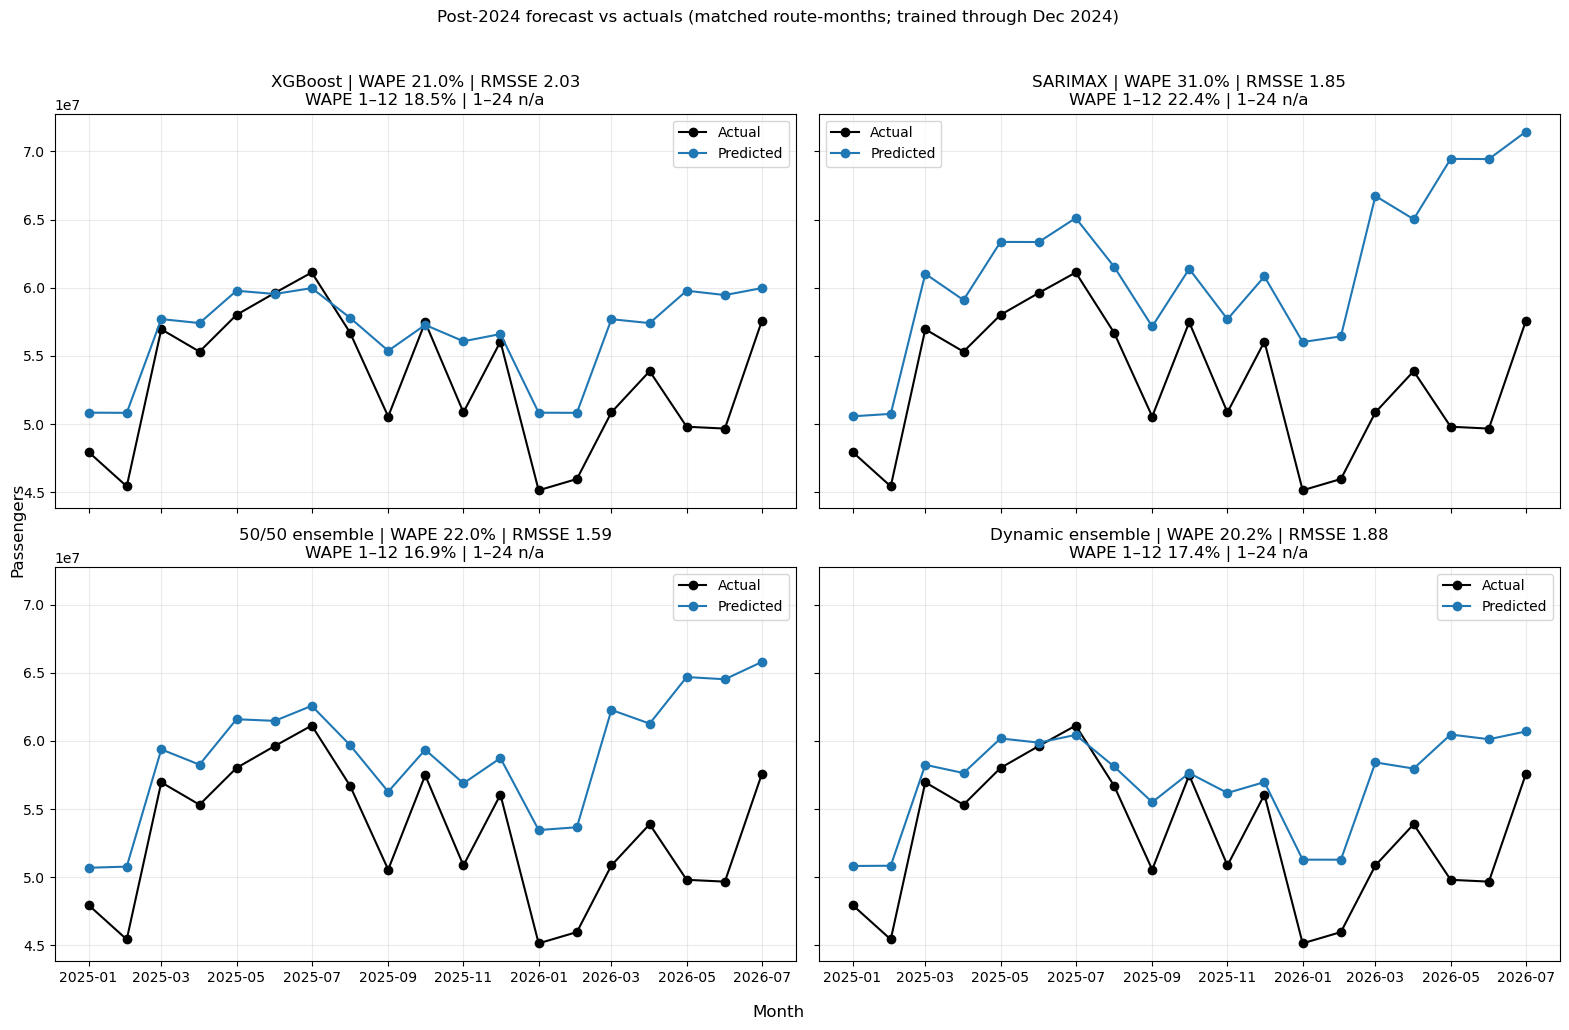

,Model,WAPE,WAPE_1_12,WAPE_1_24,MAE,Bias,RMSSE,RMSSE_Routes,RMSSE_Route_Coverage,Actual_Volume_Coverage
0,Dynamic ensemble,0.201971,0.174278,NaN,627.130076,0.072992,1.879749,17119,1.0,1.0
1,XGBoost,0.209537,0.185048,NaN,650.623359,0.065625,2.027317,17119,1.0,1.0
2,50/50 ensemble,0.220342,0.169253,NaN,684.173632,0.111281,1.588058,17119,1.0,1.0
3,SARIMAX,0.310190,0.223987,NaN,963.156070,0.156074,1.850304,17119,1.0,1.0


In [ ]:
from IPython.display import display

importlib.reload(forecasting_module)
# The historical feature-selection table scores only six validation months.
validation_columns = feature_validation_metrics.columns.union(["WAPE_1_12", "WAPE_1_24"], sort=False)
display(feature_validation_metrics.reindex(columns=validation_columns))
historical_model_metrics = forecasting_module._add_wape_windows(
    historical_model_metrics, historical_evaluation, TARGET
)

historical_monthly_comparison = historical_evaluation.groupby(
    MONTH, as_index=False
)[[TARGET] + list(historical_prediction_columns.values())].sum()

fig, axes = plt.subplots(2, 2, figsize=(16, 10), sharex=True, sharey=True)
axes = axes.ravel()
metric_lookup = historical_model_metrics.set_index("Model")
for axis, (model_name, prediction_column) in zip(
    axes, historical_prediction_columns.items()
):
    axis.plot(
        historical_monthly_comparison[MONTH],
        historical_monthly_comparison[TARGET],
        color="black",
        marker="o",
        label="Actual",
    )
    axis.plot(
        historical_monthly_comparison[MONTH],
        historical_monthly_comparison[prediction_column],
        marker="o",
        label="Predicted",
    )
    model_metrics = metric_lookup.loc[model_name]
    axis.set_title(
        f"{model_name} | WAPE {model_metrics['WAPE']:.1%} "
        f"| RMSSE {model_metrics['RMSSE']:.2f}\n"
        f"{forecasting_module._wape_window_label(model_metrics)}"
    )
    axis.grid(True, alpha=0.25)
    axis.legend()

fig.suptitle(
    "Post-2024 forecast vs actuals (matched route-months; trained through Dec 2024)",
    y=1.02,
)
fig.supxlabel("Month")
fig.supylabel("Passengers")
fig.tight_layout()
plt.show()

historical_model_metrics